## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00334ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.27s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.31s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_vol_attin 1.1 [99ba1b33|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_vol_attin 1.1 [99ba1b33|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: ==================================================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_attin 44e7d5d8/.
00: Launching 'AEC train_sqrtVar_vol_attin 1.1 [99ba1b33|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 256 for valuation. The model has 56161 parameters.
00: Training 'train_sqrtVar_vol_attin' epoch 1/1000 error avg trn 928.1; val 127.7/194.2 [11s 1.7s 0.4s]. LR: 1.00e-03, GN 59.26, excess_weighted: 1.735e-13/3.086e-13, excess_weighted_avg: 0.00759/0.0092, excess_spread: 51.39/85.96,

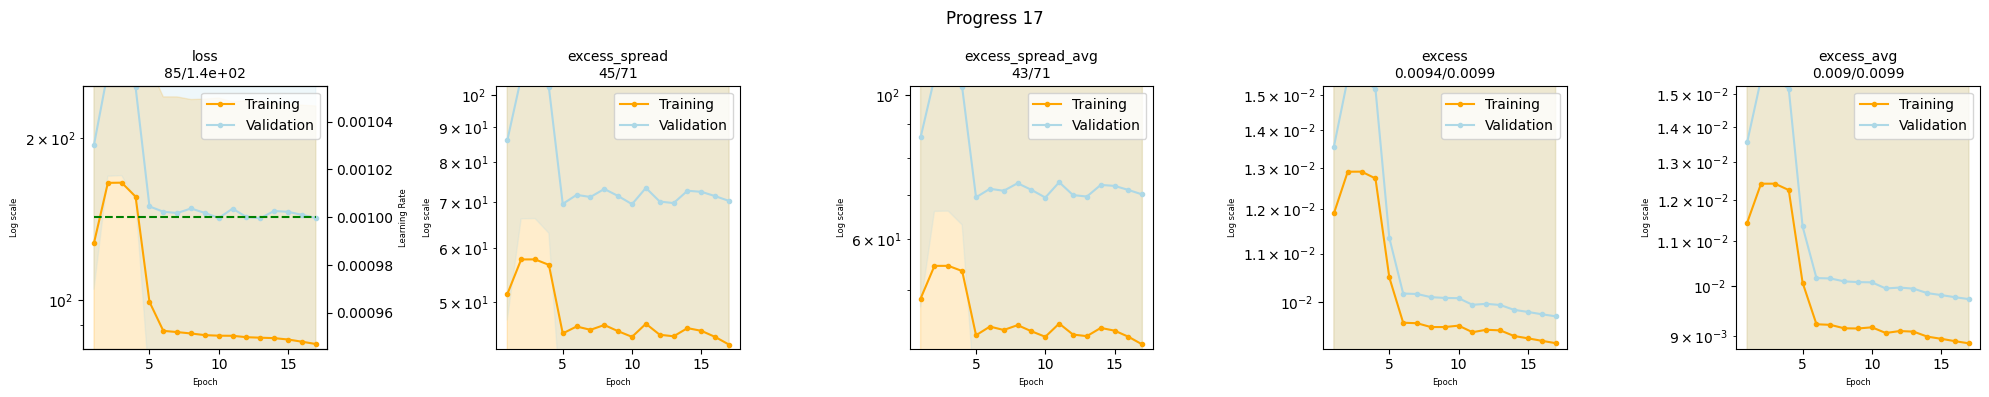

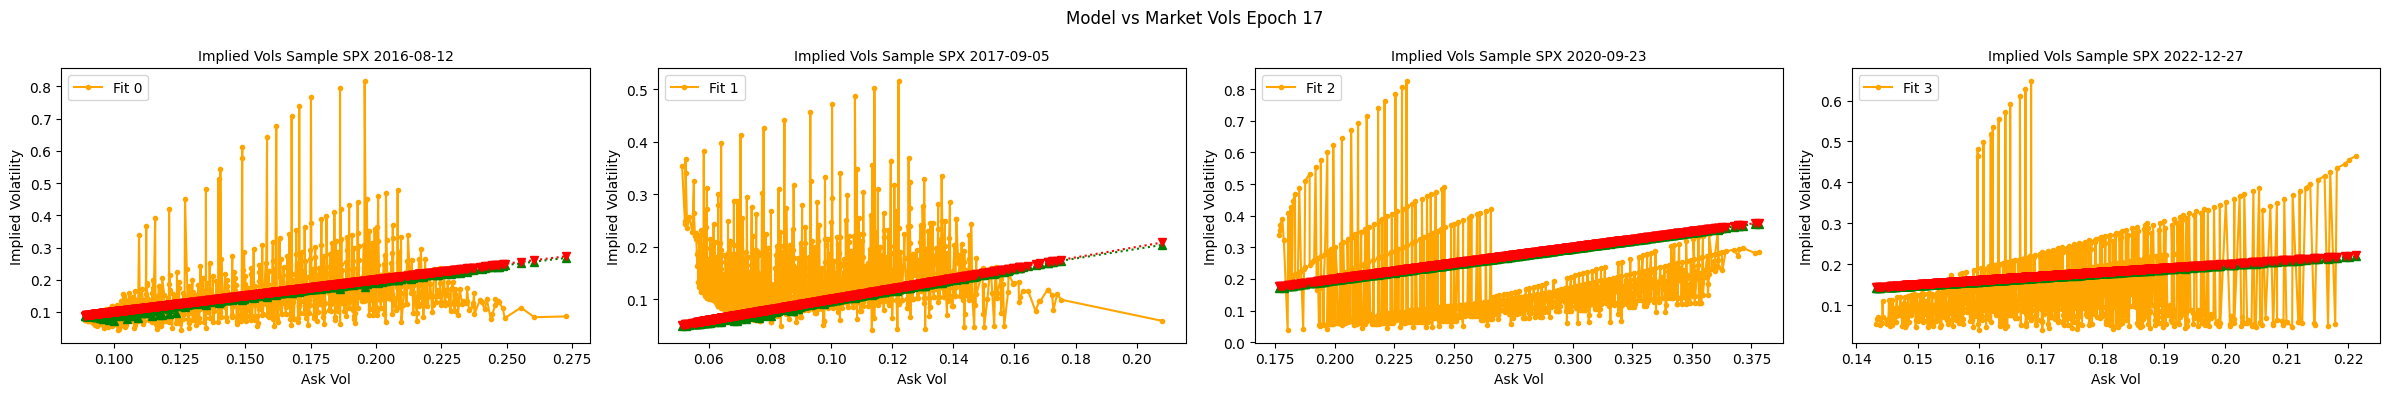

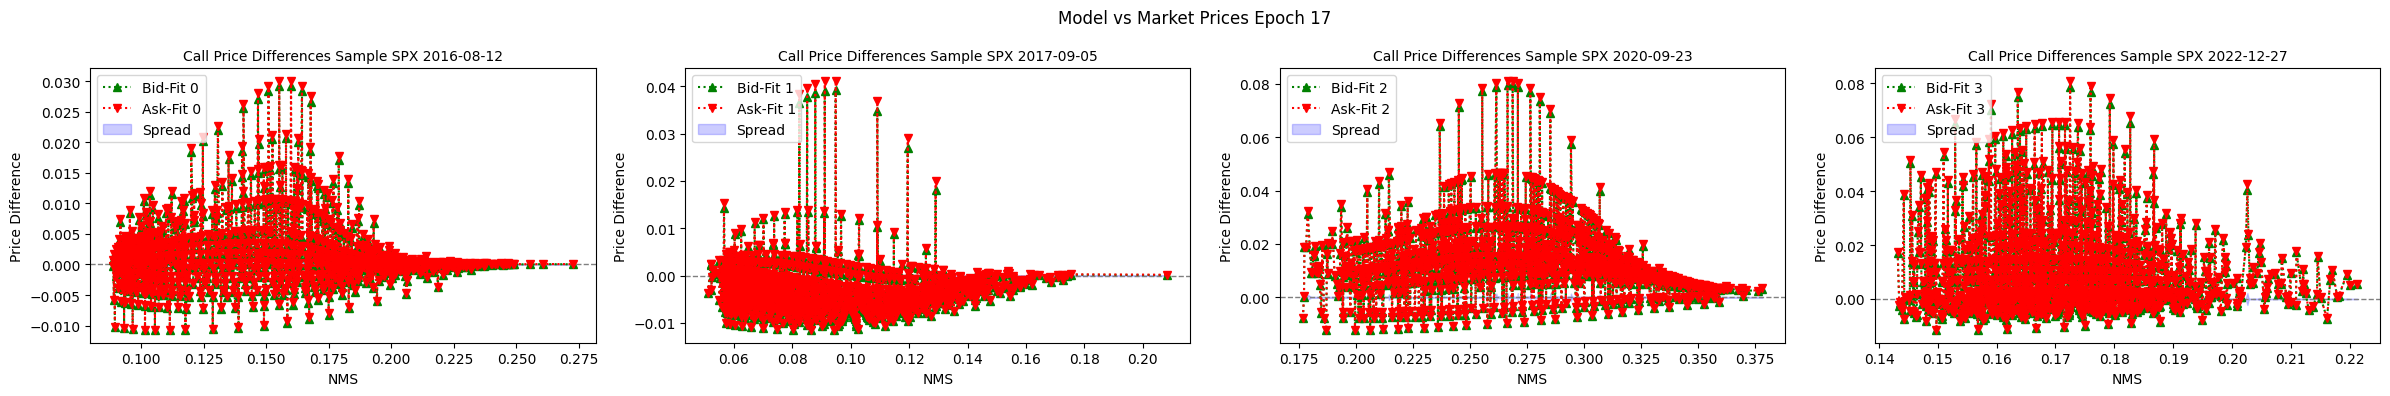

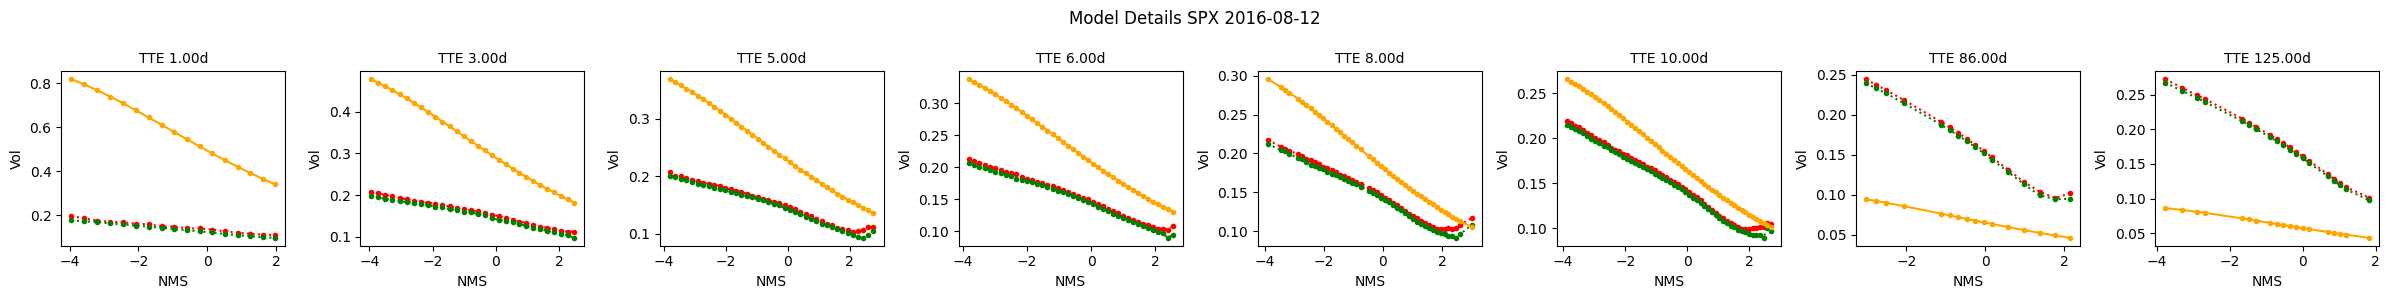

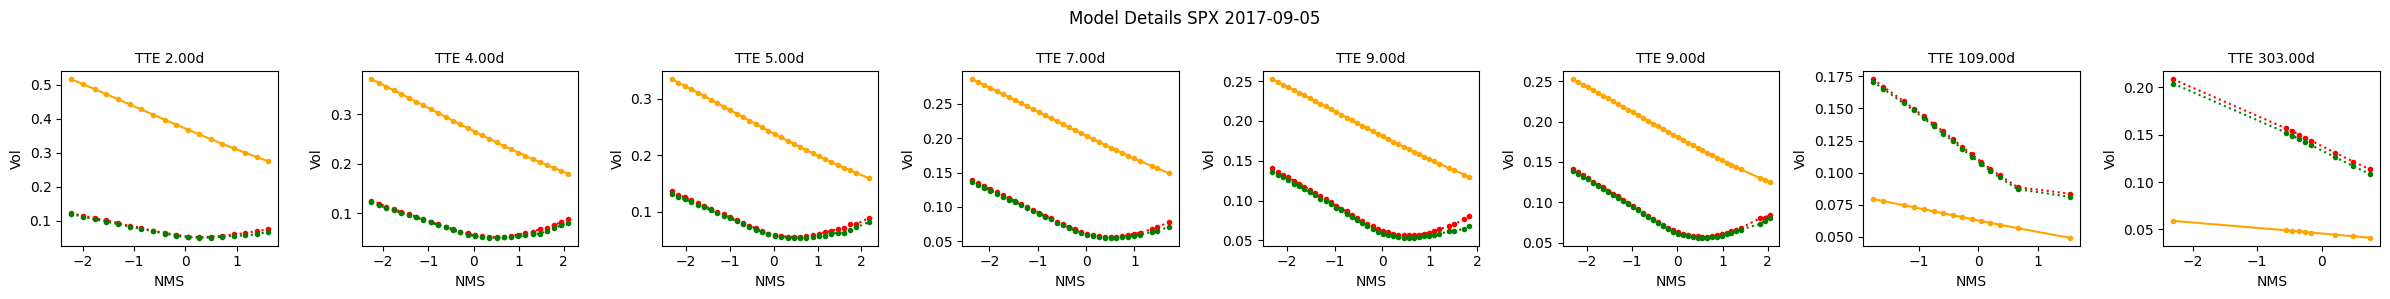

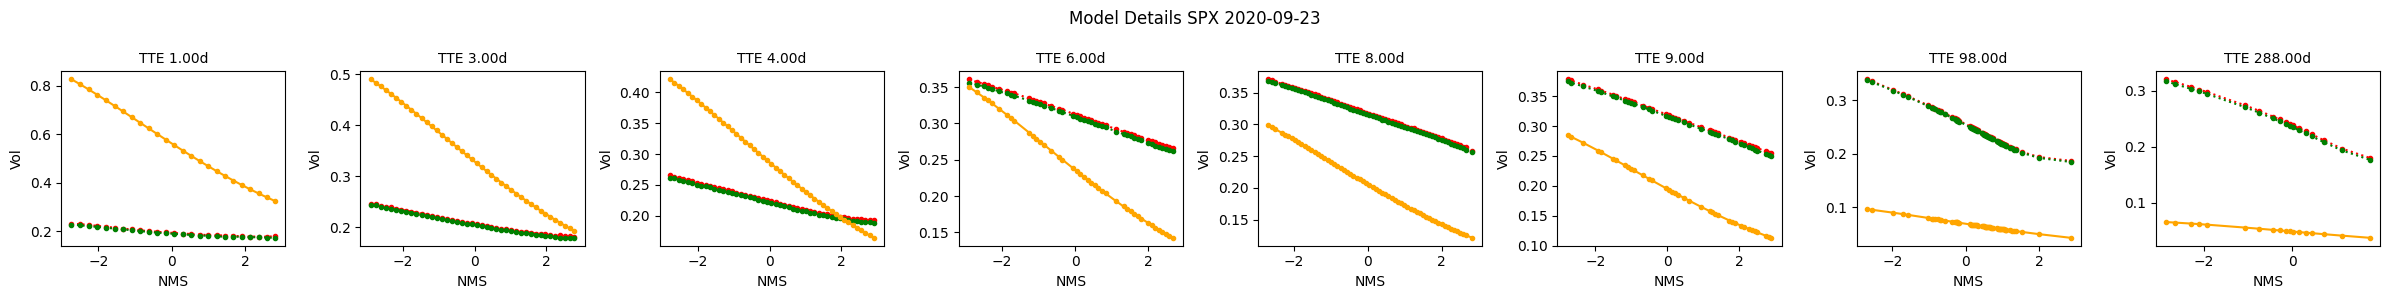

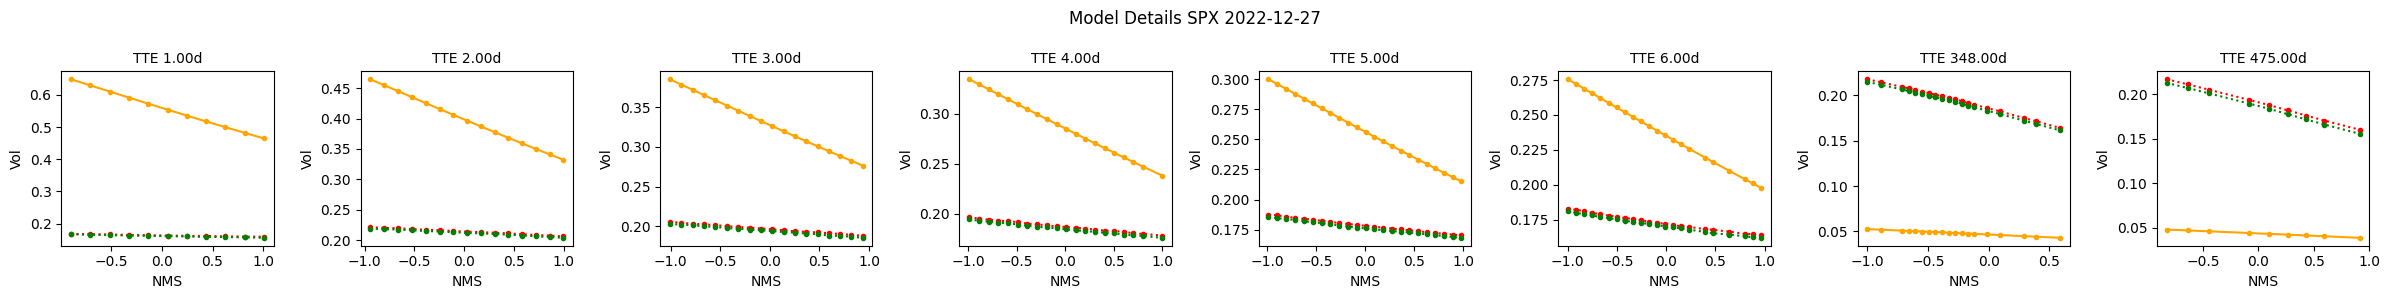

00: Training 'train_sqrtVar_vol_attin' epoch 2/1000 error avg trn 155.1; val 165/265.3 [11s 1.7s 0.4s]. LR: 1.00e-03, GN 13.48, excess_weighted: 1.948e-13/3.808e-13, excess_weighted_avg: 0.00837/0.01118, excess_spread: 57.72/106.1, excess_spread_avg: 54.5/106.1, excess: 0.01291/0.01549, excess_avg: 0.01242/0.01549. ETA: 8:25:41.
00: Training 'train_sqrtVar_vol_attin' epoch 3/1000 error avg trn 166.4; val 165.1/265.7 [11s 1.6s 0.4s]. LR: 1.00e-03, GN 12.3, excess_weighted: 1.948e-13/3.811e-13, excess_weighted_avg: 0.008371/0.01118, excess_spread: 57.73/106.1, excess_spread_avg: 54.51/106.1, excess: 0.01291/0.0155, excess_avg: 0.01242/0.0155. ETA: 12:47:33.
00: Training 'train_sqrtVar_vol_attin' epoch 4/1000 error avg trn 163.5; val 155.6/248.2 [11s 1.6s 0.4s]. LR: 1.00e-03, GN 22.15, excess_weighted: 1.913e-13/3.686e-13, excess_weighted_avg: 0.008245/0.01085, excess_spread: 56.68/102.7, excess_spread_avg: 53.52/102.7, excess: 0.01274/0.01518, excess_avg: 0.01225/0.01518. ETA: 17:05:01.


In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,

    encoder = AttentionEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 10, debug=False, val_batch_size=256 )
